<a href="https://colab.research.google.com/github/senanayakenithikas-ux/cm2604-churn-prediction/blob/main/01_eda.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [3]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import os
sns.set_theme(style="whitegrid")
os.makedirs("figures", exist_ok=True)

In [4]:
url = "https://raw.githubusercontent.com/senanayakenithikas-ux/cm2604-churn-prediction/main/data/WA_Fn-UseC_-Telco-Customer-Churn.csv"
df = pd.read_csv(url)
df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


## 1. Data inspection and cleaning

In [5]:
# Rows/columns, data types and non-null counts
print(df.shape)
df.info()

(7043, 21)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null

In [6]:
# TotalCharges is text because some rows are blank " ". Convert: blanks -> NaN
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")
print("Missing TotalCharges:", df["TotalCharges"].isna().sum())

# Who are these customers?
df[df["TotalCharges"].isna()][["tenure", "MonthlyCharges", "TotalCharges"]]

Missing TotalCharges: 11


,tenure,MonthlyCharges,TotalCharges
488,0,52.55,NaN
753,0,20.25,NaN
936,0,80.85,NaN
1082,0,25.75,NaN
1340,0,56.05,NaN
3331,0,19.85,NaN
3826,0,25.35,NaN
4380,0,20.00,NaN
5218,0,19.70,NaN
6670,0,73.35,NaN


In [7]:
# Tenure 0 = new customers not billed yet, so their true total is 0
df["TotalCharges"] = df["TotalCharges"].fillna(0)
print("Missing now:", df["TotalCharges"].isna().sum())
print("Duplicate customers:", df["customerID"].duplicated().sum())

Missing now: 0
Duplicate customers: 0


df.info() showed TotalCharges stored as text (object), even though it holds money. Converting it with pd.to_numeric(errors="coerce") revealed 11 blank values. All 11 customers had tenure = 0, meaning they were new and had not received a bill yet, so I filled them with 0 rather than the mean (the mean would invent charges they never paid). No duplicate customers were found.

## 2. Target variable: churn distribution

       count  percent
Churn                
No      5174     73.5
Yes     1869     26.5


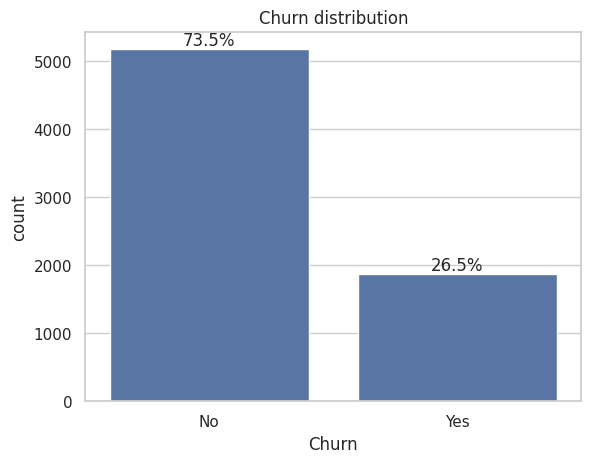

In [8]:
# Count and percentage of each class
counts = df["Churn"].value_counts()
pct = df["Churn"].value_counts(normalize=True) * 100
print(pd.DataFrame({"count": counts, "percent": pct.round(1)}))

ax = sns.countplot(data=df, x="Churn", order=["No", "Yes"])
# Label each bar with its percentage
for bar, p in zip(ax.patches, pct[["No", "Yes"]]):
    ax.annotate(f"{p:.1f}%", (bar.get_x() + bar.get_width()/2, bar.get_height()),
                ha="center", va="bottom")
plt.title("Churn distribution")
plt.savefig("figures/churn_distribution.png", dpi=150, bbox_inches="tight")  # save BEFORE show
plt.show()

The target variable is Churn (Yes/No). 73.5% of customers stayed and only 26.5% churned, so the dataset is imbalanced (about 3:1). A model that always predicts “No” would reach 73.5% accuracy without finding a single churner, so accuracy alone is misleading. I will evaluate models with recall, F1-score and ROC-AUC, and use a stratified train/test split to keep this ratio.

## 3. Churn rate by categorical features

In [9]:
overall_rate = (df["Churn"] == "Yes").mean() * 100

def churn_rate_plot(col):
    # % of customers in each group who churned
    rate = (df.groupby(col)["Churn"]
              .apply(lambda s: (s == "Yes").mean() * 100)
              .sort_values(ascending=False))

    ax = rate.plot(kind="bar", color="steelblue")
    ax.axhline(overall_rate, color="red", linestyle="--", label="Overall churn rate")
    ax.set_ylabel("Churn rate (%)")
    ax.set_title(f"Churn rate by {col}")
    ax.legend()
    plt.xticks(rotation=30, ha="right")
    plt.savefig(f"figures/churn_by_{col}.png", dpi=150, bbox_inches="tight")
    plt.show()
    print(rate.round(1))

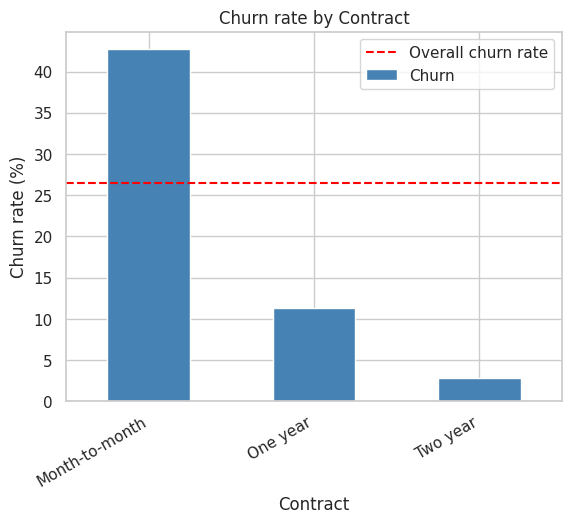

Contract
Month-to-month    42.7
One year          11.3
Two year           2.8
Name: Churn, dtype: float64


In [10]:
churn_rate_plot("Contract")

Month-to-month customers churn at 42.7%, well above the overall rate of 26.5%, compared to 11.3% for one-year and only 2.8% for two-year contracts, about 15 times lower. Month-to-month customers have no commitment and can leave easily, while long contracts strongly retain customers. Contract is therefore likely to be a key predictor of churn.

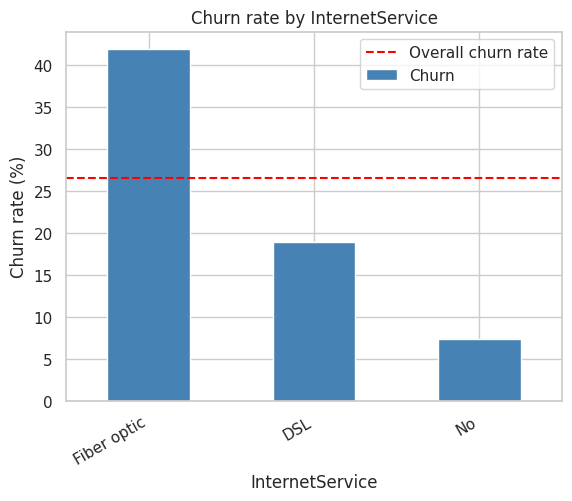

InternetService
Fiber optic    41.9
DSL            19.0
No              7.4
Name: Churn, dtype: float64


In [11]:
churn_rate_plot("InternetService")

Fiber optic customers churn at 41.9%, well above the overall rate of 26.5% and more than double DSL customers (19.0%), while customers with no internet service churn at only 7.4%. Fiber is the more expensive service, so higher prices or dissatisfaction with service quality may be reasons. However, this is an association, not proof of cause, since fiber customers also tend to have higher monthly charges. InternetService is likely a strong predictor of churn.

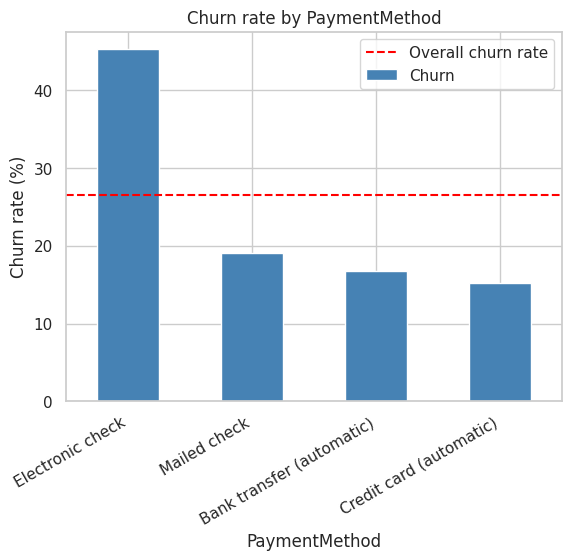

PaymentMethod
Electronic check             45.3
Mailed check                 19.1
Bank transfer (automatic)    16.7
Credit card (automatic)      15.2
Name: Churn, dtype: float64


In [12]:
churn_rate_plot("PaymentMethod")

Customers paying by electronic check churn at 45.3%, well above the overall rate of 26.5% and about three times higher than customers using automatic credit card payments (15.2%) or bank transfers (16.7%). Interestingly, mailed check is also a manual payment method but has a much lower churn rate (19.1%), so manual payment alone does not explain the high churn among electronic check users. Customers on automatic payments may be more settled and committed, while electronic check users could be newer or on month-to-month contracts, although this is an association rather than proof of cause. PaymentMethod is therefore likely to be a useful predictor of churn.

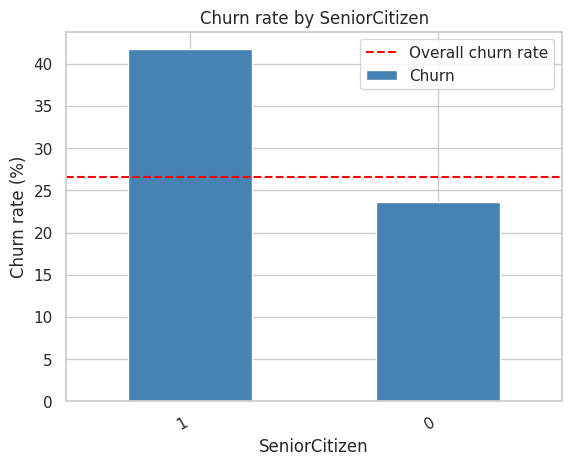

SeniorCitizen
1    41.7
0    23.6
Name: Churn, dtype: float64


In [13]:
churn_rate_plot("SeniorCitizen")

Senior citizens churn at 41.7%, well above the overall rate of 26.5% and almost double non-seniors (23.6%). Possible reasons include difficulty using the services or greater sensitivity to price, although this is an association rather than proof of cause. Seniors make up a small share of customers, and the difference (18 points) is smaller than for Contract (40 points), so SeniorCitizen is a useful but weaker predictor.

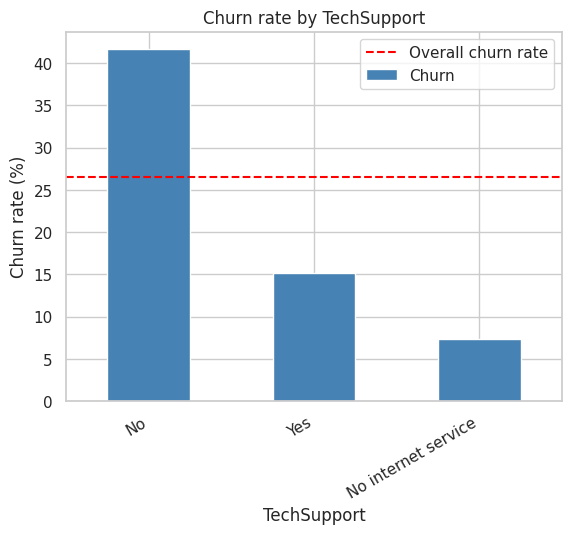

TechSupport
No                     41.6
Yes                    15.2
No internet service     7.4
Name: Churn, dtype: float64


In [14]:
churn_rate_plot("TechSupport")

Customers without tech support churn at 41.6%, well above the overall rate of 26.5% and nearly three times higher than customers with tech support (15.2%). Customers with no internet service churn least (7.4%), as they cannot use add-on services at all. Similar patterns appear for other add-ons such as OnlineSecurity and OnlineBackup, suggesting that customers who use support and protection services are more engaged and less likely to leave. This is an association rather than proof of cause, but TechSupport is likely a strong predictor of churn.